In [1]:
import pandas as pd
import requests
from bs4 import BeautifulSoup
import re
import string
import matplotlib.pyplot as plt
from collections import Counter
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer

ModuleNotFoundError: No module named 'bs4'

In [ ]:
original = pd.read_csv('news_summary.csv', encoding='ISO-8859-1') #Both ISO-8859-1 and cp1252 seem to work

# print(original.info()) #The info is consistent with the kaggle website

****
Check and fill missing data
****

In [ ]:
print('Missing data:')

missing = original.isnull().sum()
print(missing.to_string())

Missing data:
author         0
date           0
headlines      0
read_more      0
text           0
ctext        118


In [ ]:
# missing_ctext = original[original['ctext'].isnull()]
# failed_redirects = []
# failed_soup = []
# empty = []
# success = 0

# #All missing ctext seems to come from the same website
# for i, row in missing_ctext.iterrows():

#     try:
#         output = ''
#         url = row['read_more']
#         response = requests.get(url)
#         soup = BeautifulSoup(response.content, 'lxml')

#         #https://www.indiatoday.in/ format
#         container = soup.find('div', class_='jsx-ace90f4eca22afc7 Story_description__fq_4S description paywall')

#         if container:
#             content = container.find_all('p')

#             for text in content: output = output + text.text
#             output = output.strip()

#             if string:
#                 # print(output)
#                 original.at[i, 'ctext'] = output
#                 success += 1
#             else:
#                 empty.append([i, row['read_more']])

#         else:
#             failed_soup.append([i, row['read_more']])
    
#     except requests.exceptions.RequestException as e:
#         failed_redirects.append([i, row['read_more']])
#         continue

# # print(failed_redirects)
# # print(failed_soup)
# # print(empty)
# print(f'Number of success: {success}')
# print(f'Number of redirect failes: {len(failed_redirects)}')
# print(f'Number of empty articles: {len(empty)}')
# print(f'Number of failed soup or in most cases redirected to home site because of requests: {len(failed_soup)}')

In [ ]:
filled = original.dropna().copy()

print('Missing data:')

missing = filled.isnull().sum()
print(missing.to_string())

Missing data:
author       0
date         0
headlines    0
read_more    0
text         0
ctext        0


****
Remove Duplicates
****

In [ ]:
print(f"Duplicate rows: {filled.duplicated().sum()}")

unique = filled.copy()
unique.drop_duplicates(inplace=True)

Duplicate rows: 0


****
Cleaning
****

***
Standardizing?
***

In [ ]:
cleaned = unique.copy()

In [ ]:
def clean(text):
    text = text.lower()
    text = re.sub(r'\s+', ' ', text)  #collapse whitespace
    text = re.sub(f"[{re.escape(string.punctuation)}]", "", text)  #remove punctuation
    return text.strip()

In [ ]:
cleaned['ctext'] = cleaned['ctext'].apply(clean)
cleaned.head()

,author,date,headlines,read_more,text,ctext
0,Chhavi Tyagi,"03 Aug 2017,Thursday",Daman & Diu revokes mandatory Rakshabandhan in...,http://www.hindustantimes.com/india-news/raksh...,The Administration of Union Territory Daman an...,the daman and diu administration on wednesday ...
1,Daisy Mowke,"03 Aug 2017,Thursday",Malaika slams user who trolled her for 'divorc...,http://www.hindustantimes.com/bollywood/malaik...,Malaika Arora slammed an Instagram user who tr...,from her special numbers to tvappearances boll...
2,Arshiya Chopra,"03 Aug 2017,Thursday",'Virgin' now corrected to 'Unmarried' in IGIMS...,http://www.hindustantimes.com/patna/bihar-igim...,The Indira Gandhi Institute of Medical Science...,the indira gandhi institute of medical science...
3,Sumedha Sehra,"03 Aug 2017,Thursday",Aaj aapne pakad liya: LeT man Dujana before be...,http://indiatoday.intoday.in/story/abu-dujana-...,Lashkar-e-Taiba's Kashmir commander Abu Dujana...,lashkaretaibas kashmir commander abu dujana wa...
4,Aarushi Maheshwari,"03 Aug 2017,Thursday",Hotel staff to get training to spot signs of s...,http://indiatoday.intoday.in/story/sex-traffic...,Hotels in Maharashtra will train their staff t...,hotels in mumbai and other indian cities are t...


***
Lowercase
***

In [ ]:
def lowercase(text):
    return text.lower()

In [ ]:
cleaned['ctext'] = cleaned['ctext'].apply(clean)
cleaned.head()

,author,date,headlines,read_more,text,ctext
0,Chhavi Tyagi,"03 Aug 2017,Thursday",Daman & Diu revokes mandatory Rakshabandhan in...,http://www.hindustantimes.com/india-news/raksh...,The Administration of Union Territory Daman an...,the daman and diu administration on wednesday ...
1,Daisy Mowke,"03 Aug 2017,Thursday",Malaika slams user who trolled her for 'divorc...,http://www.hindustantimes.com/bollywood/malaik...,Malaika Arora slammed an Instagram user who tr...,from her special numbers to tvappearances boll...
2,Arshiya Chopra,"03 Aug 2017,Thursday",'Virgin' now corrected to 'Unmarried' in IGIMS...,http://www.hindustantimes.com/patna/bihar-igim...,The Indira Gandhi Institute of Medical Science...,the indira gandhi institute of medical science...
3,Sumedha Sehra,"03 Aug 2017,Thursday",Aaj aapne pakad liya: LeT man Dujana before be...,http://indiatoday.intoday.in/story/abu-dujana-...,Lashkar-e-Taiba's Kashmir commander Abu Dujana...,lashkaretaibas kashmir commander abu dujana wa...
4,Aarushi Maheshwari,"03 Aug 2017,Thursday",Hotel staff to get training to spot signs of s...,http://indiatoday.intoday.in/story/sex-traffic...,Hotels in Maharashtra will train their staff t...,hotels in mumbai and other indian cities are t...


****
More Columns
****

***
Char Length
***

In [ ]:
cleaned['ctext_length'] = cleaned['ctext'].apply(len)
cleaned.head()

,author,date,headlines,read_more,text,ctext,ctext_length
0,Chhavi Tyagi,"03 Aug 2017,Thursday",Daman & Diu revokes mandatory Rakshabandhan in...,http://www.hindustantimes.com/india-news/raksh...,The Administration of Union Territory Daman an...,the daman and diu administration on wednesday ...,2256
1,Daisy Mowke,"03 Aug 2017,Thursday",Malaika slams user who trolled her for 'divorc...,http://www.hindustantimes.com/bollywood/malaik...,Malaika Arora slammed an Instagram user who tr...,from her special numbers to tvappearances boll...,2291
2,Arshiya Chopra,"03 Aug 2017,Thursday",'Virgin' now corrected to 'Unmarried' in IGIMS...,http://www.hindustantimes.com/patna/bihar-igim...,The Indira Gandhi Institute of Medical Science...,the indira gandhi institute of medical science...,2045
3,Sumedha Sehra,"03 Aug 2017,Thursday",Aaj aapne pakad liya: LeT man Dujana before be...,http://indiatoday.intoday.in/story/abu-dujana-...,Lashkar-e-Taiba's Kashmir commander Abu Dujana...,lashkaretaibas kashmir commander abu dujana wa...,2296
4,Aarushi Maheshwari,"03 Aug 2017,Thursday",Hotel staff to get training to spot signs of s...,http://indiatoday.intoday.in/story/sex-traffic...,Hotels in Maharashtra will train their staff t...,hotels in mumbai and other indian cities are t...,3182


***
Word Count
***

In [ ]:
def word_count(text):
    word_list = text.split()
    return len(word_list)

In [ ]:
cleaned['ctext_word_count'] = cleaned['ctext'].apply(word_count)
cleaned.head()

,author,date,headlines,read_more,text,ctext,ctext_length,ctext_word_count
0,Chhavi Tyagi,"03 Aug 2017,Thursday",Daman & Diu revokes mandatory Rakshabandhan in...,http://www.hindustantimes.com/india-news/raksh...,The Administration of Union Territory Daman an...,the daman and diu administration on wednesday ...,2256,362
1,Daisy Mowke,"03 Aug 2017,Thursday",Malaika slams user who trolled her for 'divorc...,http://www.hindustantimes.com/bollywood/malaik...,Malaika Arora slammed an Instagram user who tr...,from her special numbers to tvappearances boll...,2291,395
2,Arshiya Chopra,"03 Aug 2017,Thursday",'Virgin' now corrected to 'Unmarried' in IGIMS...,http://www.hindustantimes.com/patna/bihar-igim...,The Indira Gandhi Institute of Medical Science...,the indira gandhi institute of medical science...,2045,334
3,Sumedha Sehra,"03 Aug 2017,Thursday",Aaj aapne pakad liya: LeT man Dujana before be...,http://indiatoday.intoday.in/story/abu-dujana-...,Lashkar-e-Taiba's Kashmir commander Abu Dujana...,lashkaretaibas kashmir commander abu dujana wa...,2296,403
4,Aarushi Maheshwari,"03 Aug 2017,Thursday",Hotel staff to get training to spot signs of s...,http://indiatoday.intoday.in/story/sex-traffic...,Hotels in Maharashtra will train their staff t...,hotels in mumbai and other indian cities are t...,3182,521


***
Average Word Length
***

In [ ]:
def word_length(text):
    total = 0
    for word in text.split():
        total += len(word)

    if len(text.split()) == 0:
        return 0
    
    average = total / len(text.split())
    return average

In [ ]:
cleaned['ctext_average_word_length'] = cleaned['ctext'].apply(word_length)
cleaned.head()

,author,date,headlines,read_more,text,ctext,ctext_length,ctext_word_count,ctext_average_word_length
0,Chhavi Tyagi,"03 Aug 2017,Thursday",Daman & Diu revokes mandatory Rakshabandhan in...,http://www.hindustantimes.com/india-news/raksh...,The Administration of Union Territory Daman an...,the daman and diu administration on wednesday ...,2256,362,5.234807
1,Daisy Mowke,"03 Aug 2017,Thursday",Malaika slams user who trolled her for 'divorc...,http://www.hindustantimes.com/bollywood/malaik...,Malaika Arora slammed an Instagram user who tr...,from her special numbers to tvappearances boll...,2291,395,4.802532
2,Arshiya Chopra,"03 Aug 2017,Thursday",'Virgin' now corrected to 'Unmarried' in IGIMS...,http://www.hindustantimes.com/patna/bihar-igim...,The Indira Gandhi Institute of Medical Science...,the indira gandhi institute of medical science...,2045,334,5.125749
3,Sumedha Sehra,"03 Aug 2017,Thursday",Aaj aapne pakad liya: LeT man Dujana before be...,http://indiatoday.intoday.in/story/abu-dujana-...,Lashkar-e-Taiba's Kashmir commander Abu Dujana...,lashkaretaibas kashmir commander abu dujana wa...,2296,403,4.699752
4,Aarushi Maheshwari,"03 Aug 2017,Thursday",Hotel staff to get training to spot signs of s...,http://indiatoday.intoday.in/story/sex-traffic...,Hotels in Maharashtra will train their staff t...,hotels in mumbai and other indian cities are t...,3182,521,5.109405


***
Visualize Simple Stats
***

In [ ]:
def visualize(col):
    plt.figure(figsize=(20, 6))
    
    plt.subplot(1,2,1)
    sns.boxplot(y=cleaned[col])
    plt.ylabel(col, labelpad=12.5)
    
    plt.subplot(1,2,2)
    sns.kdeplot(cleaned[col])
    plt.xlabel('')
    plt.ylabel('')
    
    plt.show()

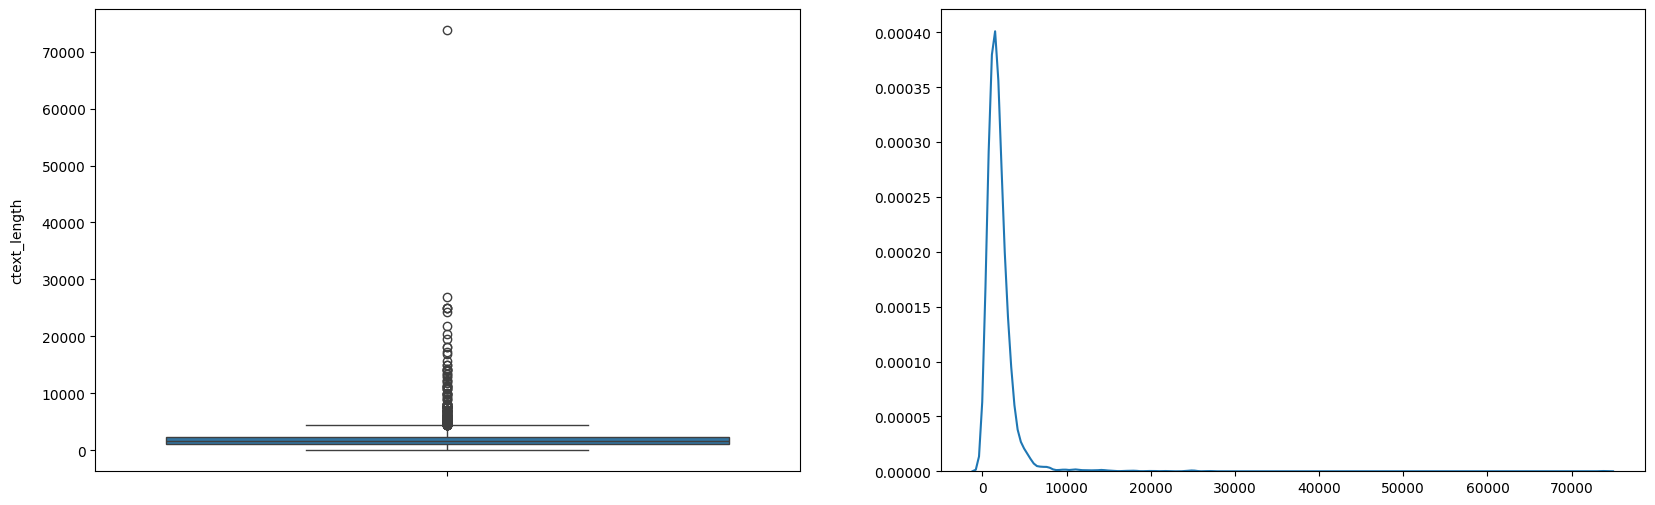

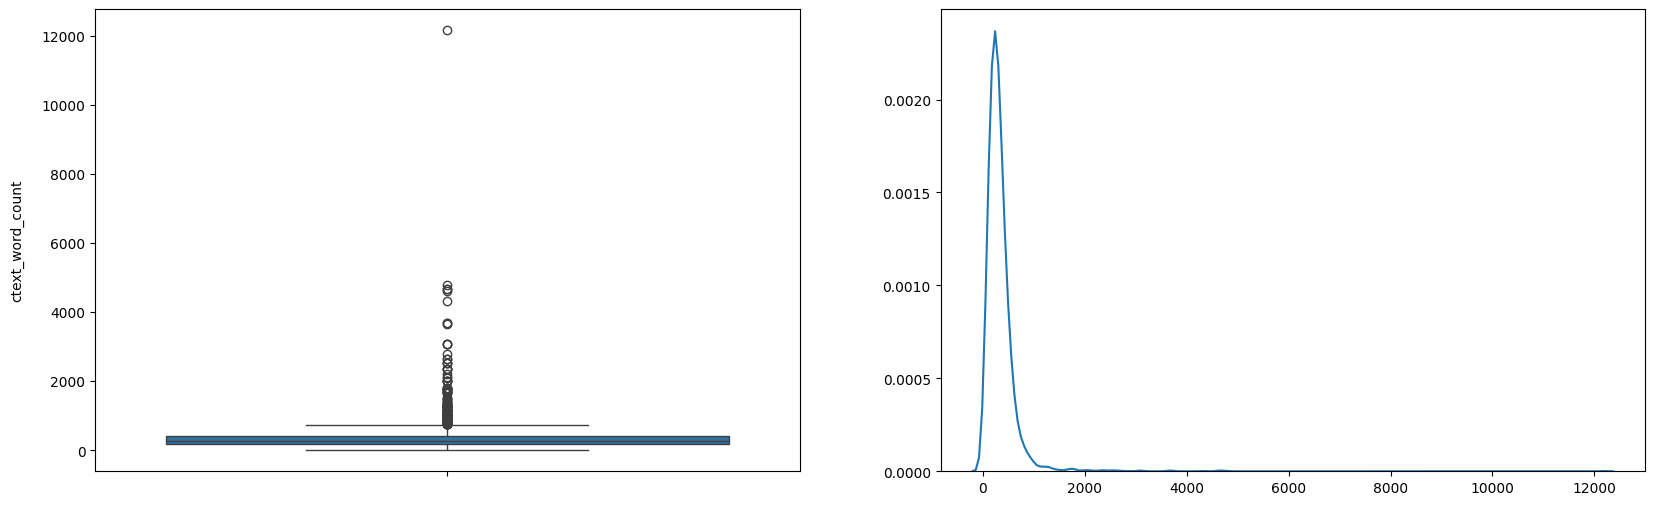

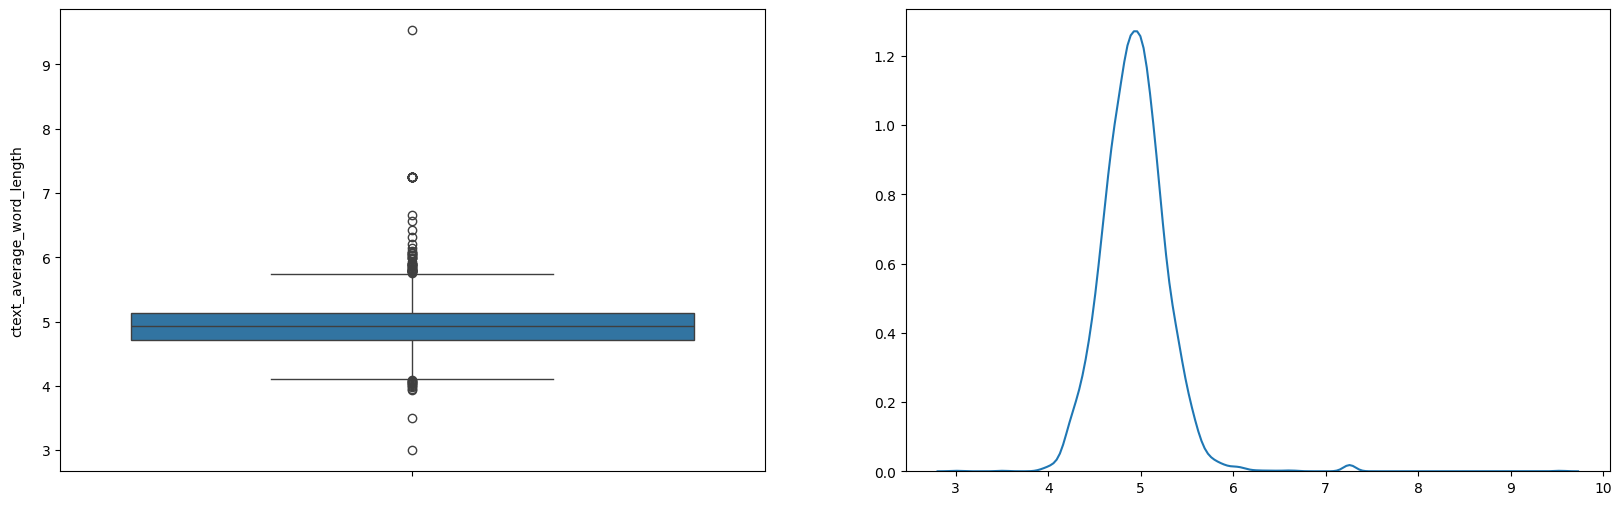

In [ ]:
stats = cleaned.columns.tolist()[6:]

for feature in stats:
    visualize(feature)

***
Stats
***

***
Vocab Size
***

In [ ]:
all_words = ' '.join(cleaned['ctext']).split()

vocab_size = len(set(all_words))
print(f"Vocabulary Size: {vocab_size}")

Vocabulary Size: 80096


***
Visualization
***

***
Frequent Words
***

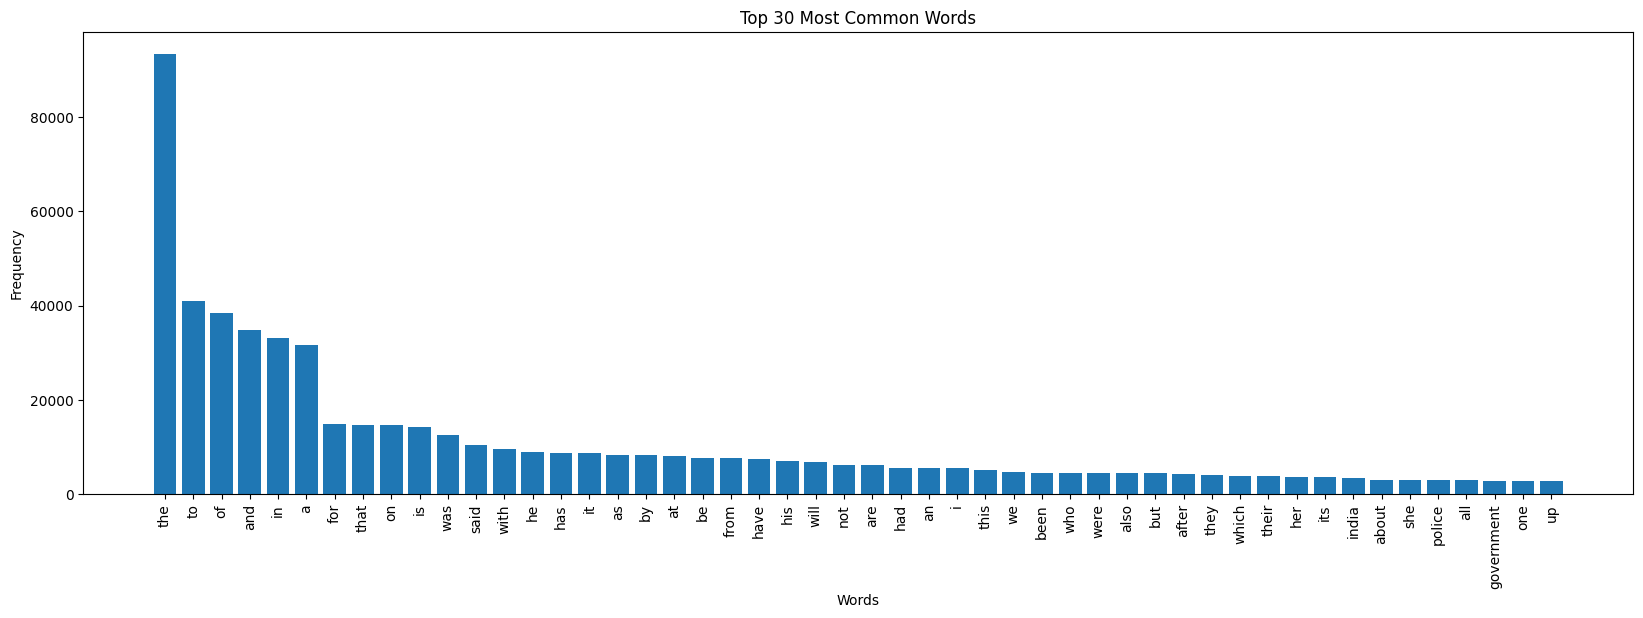

In [ ]:
word_counts = Counter(all_words)

most_common = word_counts.most_common(50)
words, counts = zip(*most_common)

plt.figure(figsize=(20, 6))
plt.bar(words, counts)
plt.xticks(rotation=90)
plt.title('Top 50 Most Common Words')
plt.xlabel('Words')
plt.ylabel('Frequency')
plt.show()

***
Frequent Bigrams
***

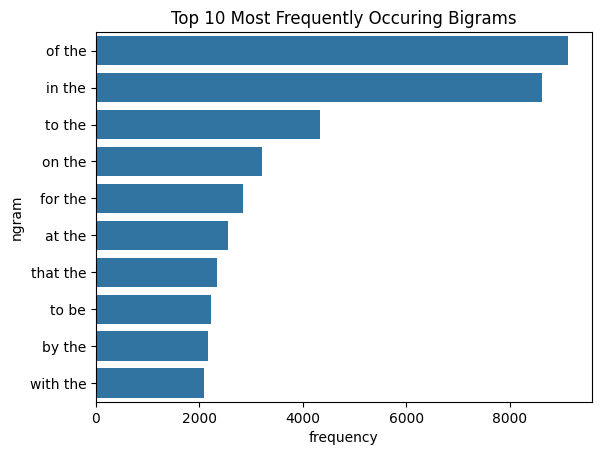

In [ ]:
cv = CountVectorizer(ngram_range=(2,2))
bigrams = cv.fit_transform(cleaned['ctext'])

count_values = bigrams.toarray().sum(axis=0)
ngram_freq = pd.DataFrame(sorted([(count_values[i], k) for k, i in cv.vocabulary_.items()], reverse = True))
ngram_freq.columns = ["frequency", "ngram"]

sns.barplot(x=ngram_freq['frequency'][:10], y=ngram_freq['ngram'][:10])
plt.title('Top 10 Most Frequently Occuring Bigrams')
plt.show()

***
Frequent Trigrams
***

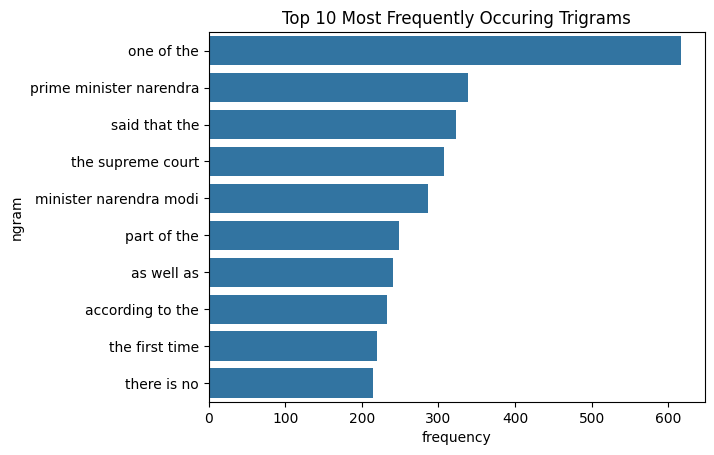

In [ ]:
cv1 = CountVectorizer(ngram_range=(3,3))
trigrams = cv1.fit_transform(cleaned['ctext'])
count_values = trigrams.toarray().sum(axis=0)
ngram_freq = pd.DataFrame(sorted([(count_values[i], k) for k, i in cv1.vocabulary_.items()], reverse = True))
ngram_freq.columns = ["frequency", "ngram"]

sns.barplot(x=ngram_freq['frequency'][:10], y=ngram_freq['ngram'][:10])
plt.title('Top 10 Most Frequently Occuring Trigrams')
plt.show()